# Triple Insight — Pre-entrega 4: Aprendizaje no supervisado

## Segmentación exploratoria de estaciones de servicio

Esta notebook es **autónoma**: carga los archivos anuales, los unifica y realiza la limpieza inicial siguiendo el procedimiento de la Pre-entrega 3. No requiere ejecutar previamente la Pre-entrega 3 ni disponer de `EESS_limpio.csv`.

Luego construye una tabla a nivel estación, excluye `nro_inscripcion` de las variables de clustering y aplica K-Means con K=4, la alternativa elegida por el equipo después de explorar K=6.

## 1. Instalar e importar librerías

In [ ]:
# Si fuera necesario:
# !pip install -q pandas numpy matplotlib seaborn scikit-learn

import glob
import re
import unicodedata
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 2. Cargar y unificar los datasets anuales

Subir a `/content/` los archivos `EESS_2018.csv` a `EESS_2024.csv`. El código busca los archivos anuales, excluye archivos de salida como `EESS_limpio.csv`, elimina identificadores previos y concatena los datasets.

In [ ]:
# Buscar todos los archivos CSV de EESS anuales del periodo 2018-2024.
# Se excluyen archivos de salida para evitar incorporarlos nuevamente.
archivos_eess = sorted([
    f for f in glob.glob("/content/EESS_*.csv")
    if not f.endswith("limpio.csv")
])

print("Archivos encontrados para unificar:", archivos_eess)

if not archivos_eess:
    raise FileNotFoundError(
        "No se encontraron archivos EESS_*.csv en /content/. "
        "Subí los CSV anuales 2018-2024 a Colab."
    )

lista_dfs = []

for archivo in archivos_eess:
    df_temp = pd.read_csv(archivo, low_memory=False)

    # Eliminar identificadores previos si existen.
    columnas_a_eliminar = [
        col for col in ["_id", "id", "id.1"]
        if col in df_temp.columns
    ]
    if columnas_a_eliminar:
        df_temp = df_temp.drop(columns=columnas_a_eliminar)

    print(
        f"Cargado {archivo} - Filas: {df_temp.shape[0]}, "
        f"Columnas restantes: {df_temp.shape[1]}"
    )
    lista_dfs.append(df_temp)

estaciones_de_servicio_unificado = pd.concat(
    lista_dfs,
    ignore_index=True
)

# Crear identificador incremental único.
estaciones_de_servicio_unificado.insert(
    0, "id", range(1, len(estaciones_de_servicio_unificado) + 1)
)

df = estaciones_de_servicio_unificado.copy()
df_original = estaciones_de_servicio_unificado.copy()

print("\nTotal filas unificadas:", df.shape[0])
print("Total columnas:", df.shape[1])
display(df.head())

Archivos encontrados para unificar: ['/content/EESS_2018.csv', '/content/EESS_2019.csv', '/content/EESS_2020.csv', '/content/EESS_2021.csv', '/content/EESS_2022.csv', '/content/EESS_2023.csv', '/content/EESS_2024.csv']
Cargado /content/EESS_2018.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2019.csv - Filas: 3500, Columnas restantes: 19
Cargado /content/EESS_2020.csv - Filas: 7750, Columnas restantes: 19
Cargado /content/EESS_2021.csv - Filas: 2250, Columnas restantes: 19
Cargado /content/EESS_2022.csv - Filas: 35000, Columnas restantes: 19
Cargado /content/EESS_2023.csv - Filas: 7500, Columnas restantes: 19
Cargado /content/EESS_2024.csv - Filas: 4250, Columnas restantes: 19

Total filas unificadas: 62500
Total columnas: 20


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,f
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,f
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,f
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,f
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,NaN,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,f


## 3. Normalizar nombres de columnas

In [ ]:
def normalizar_nombre(nombre):
    nombre = str(nombre).strip().lower()
    nombre = unicodedata.normalize("NFKD", nombre)
    nombre = "".join(
        c for c in nombre
        if not unicodedata.combining(c)
    )
    nombre = re.sub(r"[^a-z0-9]+", "_", nombre)
    return nombre.strip("_")

df.columns = [normalizar_nombre(col) for col in df.columns]

print("Columnas normalizadas:")
print(df.columns.tolist())

Columnas normalizadas:
['id', 'anio', 'mes', 'operador', 'nro_inscripcion', 'bandera', 'fecha_de_baja', 'cuit', 'tipo_negocio', 'direccion', 'localidad', 'provincia', 'producto', 'canal_de_comercializacion', 'precio_sin_impuestos', 'precio_con_impuestos', 'volumen', 'precio_surtidor', 'no_novimientos', 'exentos']


## 4. Limpiar cadenas y normalizar variables de control

In [ ]:
# Limpiar espacios en variables de texto y convertir cadenas vacías en nulos.
columnas_texto = df.select_dtypes(
    include=["object", "string"]
).columns

for col in columnas_texto:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.replace(r"\s+", " ", regex=True)
    )

df = df.replace(r"^\s*$", np.nan, regex=True)

# Replicar la normalización de variables de la Pre-entrega 3.
if "exentos" in df.columns:
    df["exentos"] = (
        df["exentos"].astype("string").str.lower()
        .map({"t": True, "f": False})
    )

if "no_movimientos" in df.columns:
    df["sin_movimientos"] = (
        df["no_movimientos"].astype("string").str.upper()
        .map({"SI": True, "NO": False})
    )

print("Limpieza de textos y normalización completadas.")
if "sin_movimientos" in df.columns:
    display(df["sin_movimientos"].value_counts(dropna=False))

Limpieza de textos y normalización completadas.


## 5. Aplicar los criterios de limpieza de la Pre-entrega 3

Se excluyen los registros identificados como `sin_movimientos = True` y aquellos donde el precio sin impuestos supera al precio con impuestos. Se conservan los registros repetidos por claves de negocio, ya que pueden corresponder a distintos canales.

In [ ]:
# Excluir registros sin movimientos, como en la Pre-entrega 3.
if "sin_movimientos" in df.columns:
    cantidad_sin_movimientos = int((df["sin_movimientos"] == True).sum())
    df = df[df["sin_movimientos"] == False].copy()
    print("Registros excluidos por no tener movimientos:", cantidad_sin_movimientos)
else:
    print("No existe la columna de control sin_movimientos; no se aplica este filtro.")

# Excluir precios sin impuestos mayores que precios con impuestos.
if {"precio_sin_impuestos", "precio_con_impuestos"}.issubset(df.columns):
    df["precio_sin_impuestos"] = pd.to_numeric(
        df["precio_sin_impuestos"], errors="coerce"
    )
    df["precio_con_impuestos"] = pd.to_numeric(
        df["precio_con_impuestos"], errors="coerce"
    )

    condicion_precio_invalido = (
        df["precio_sin_impuestos"] > df["precio_con_impuestos"]
    )
    print(
        "Registros excluidos por precio sin impuestos mayor al precio con impuestos:",
        int(condicion_precio_invalido.sum())
    )
    df = df[~condicion_precio_invalido].copy()

print("Dimensiones luego de la limpieza:", df.shape)
display(df.head())

No existe la columna de control sin_movimientos; no se aplica este filtro.
Registros excluidos por precio sin impuestos mayor al precio con impuestos: 44
Dimensiones luego de la limpieza: (62456, 20)


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,False
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,False
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,False
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,False
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,False


## 6. Preparar el dataset limpio para clustering

Se conserva la estructura de la Pre-entrega 3 y se crea `df_limpio` desde los registros ya unificados y depurados. Esta notebook no depende de un CSV generado por otra notebook.

In [ ]:
df_limpio = df.copy()

print("Dimensiones originales:", df_original.shape)
print("Dimensiones después de la limpieza:", df_limpio.shape)
print("Estaciones identificadas:", df_limpio["nro_inscripcion"].nunique())
display(df_limpio.head())

Dimensiones originales: (62500, 20)
Dimensiones después de la limpieza: (62456, 20)
Estaciones identificadas: 5736


,id,anio,mes,operador,nro_inscripcion,bandera,fecha_de_baja,cuit,tipo_negocio,direccion,localidad,provincia,producto,canal_de_comercializacion,precio_sin_impuestos,precio_con_impuestos,volumen,precio_surtidor,no_novimientos,exentos
0,1,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (súper) entre 92 y 95 Ron,Al público,14.61,22.97,23.04,23.30,NO,False
1,2,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Nafta (premium) de más de 95 Ron,Al público,17.17,26.42,3.88,26.70,NO,False
2,3,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 2,Al público,13.74,20.59,13.24,20.80,NO,False
3,4,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,Gas Oil Grado 3,Al público,16.10,23.94,3.56,24.21,NO,False
4,5,2018,1,10 DE SETIEMBRE S.A.,1376,BLANCA,<NA>,33-64337382-9,Bocas de expendio (venta por menor) Duales (líquidos + GNC),Av. Mosconi 299,LOMAS DEL MIRADOR,BUENOS AIRES,GNC,Al público,7.74,10.33,"74,921.10",10.99,NO,False


## 4. Preparar la población de análisis

Se mantienen los cuatro productos frecuentes utilizados en el proyecto. Se excluyen registros sin volumen positivo y, si la columna está disponible, registros marcados como sin movimientos.

El objetivo de esta etapa es construir perfiles de estaciones, no clasificar cada registro individual de venta.

In [ ]:
productos_frecuentes = [
    "Gas Oil Grado 2",
    "Gas Oil Grado 3",
    "Nafta (súper) entre 92 y 95 Ron",
    "Nafta (premium) de más de 95 Ron"
]

df_cluster = df_limpio.copy()

df_cluster["producto"] = (
    df_cluster["producto"].astype("string").str.strip()
)

df_cluster = df_cluster[
    df_cluster["producto"].isin(productos_frecuentes)
].copy()

df_cluster["volumen"] = pd.to_numeric(
    df_cluster["volumen"], errors="coerce"
)
df_cluster["precio_surtidor"] = pd.to_numeric(
    df_cluster["precio_surtidor"], errors="coerce"
)
df_cluster["anio"] = pd.to_numeric(
    df_cluster["anio"], errors="coerce"
)

df_cluster = df_cluster[
    df_cluster["nro_inscripcion"].notna()
    & df_cluster["volumen"].gt(0)
    & df_cluster["anio"].notna()
].copy()

if "sin_movimientos" in df_cluster.columns:
    df_cluster = df_cluster[
        df_cluster["sin_movimientos"].astype(str).str.lower().isin(
            ["false", "0", "no"]
        )
    ].copy()

print("Registros después del filtro:", len(df_cluster))
print("Estaciones identificadas:", df_cluster["nro_inscripcion"].nunique())
print("Productos incluidos:", sorted(df_cluster["producto"].dropna().unique()))

Registros después del filtro: 55836
Estaciones identificadas: 4988
Productos incluidos: ['Gas Oil Grado 2', 'Gas Oil Grado 3', 'Nafta (premium) de más de 95 Ron', 'Nafta (súper) entre 92 y 95 Ron']


## 5. Construir una fila por estación

`nro_inscripcion` es un identificador, por lo tanto no debe utilizarse como una magnitud en las distancias de K-Means. Se utiliza únicamente como clave de agrupación.

Para cada estación se calcula:
- Año más reciente observado.
- Mediana del volumen de sus registros.
- Mediana del precio de surtidor disponible.

Estas variables resumen la información disponible por estación. Como los períodos son discontinuos y los precios son nominales, los perfiles son exploratorios y no representan una historia mensual completa.

In [ ]:
# Los ceros de precio_surtidor se consideran no disponibles para este análisis.
df_cluster.loc[
    df_cluster["precio_surtidor"] <= 0,
    "precio_surtidor"
] = np.nan

estaciones = (
    df_cluster
    .groupby("nro_inscripcion", as_index=False)
    .agg(
        anio_ultimo_observado=("anio", "max"),
        volumen_mediano=("volumen", "median"),
        precio_surtidor_mediano=("precio_surtidor", "median"),
        cantidad_registros=("volumen", "size"),
        cantidad_productos=("producto", "nunique")
    )
)

print("Cantidad de estaciones para clustering:", len(estaciones))
display(estaciones.head())
display(estaciones.describe().T)

Cantidad de estaciones para clustering: 4988


,nro_inscripcion,anio_ultimo_observado,volumen_mediano,precio_surtidor_mediano,cantidad_registros,cantidad_productos
0,104,2024,70.94,114.00,24,4
1,105,2022,243.44,108.35,8,4
2,107,2022,208.94,107.15,8,4
3,108,2022,10.77,108.40,8,4
4,109,2024,60.22,90.55,32,4


,count,mean,std,min,25%,50%,75%,max
nro_inscripcion,"4,988.00","5,596.03","3,328.20",104.00,"2,500.50","5,849.50","8,548.25","11,344.00"
anio_ultimo_observado,"4,988.00","2,022.43",1.03,"2,018.00","2,022.00","2,022.00","2,023.00","2,024.00"
volumen_mediano,"4,988.00",247.05,"5,040.43",0.00,21.66,51.20,91.94,"320,000.00"
precio_surtidor_mediano,"4,566.00",110.22,74.17,10.00,98.30,104.21,108.80,"1,057.00"
cantidad_registros,"4,988.00",11.19,10.70,1.00,4.00,8.00,16.00,136.00
cantidad_productos,"4,988.00",3.63,0.82,1.00,4.00,4.00,4.00,4.00


## 6. Preparar las variables para K-Means

Se excluye `nro_inscripcion` de las variables explicativas. `cantidad_registros` y `cantidad_productos` se conservan en la tabla descriptiva, pero no se incluyen en el clustering para mantener la selección de variables cuantitativas comparable con el planteo original.

El volumen y el precio suelen presentar distribuciones asimétricas. Se aplica `log1p` a ambas variables positivas antes de estandarizar. El año se mantiene en su escala original y luego también se estandariza.

In [ ]:
variables_cluster = [
    "anio_ultimo_observado",
    "volumen_mediano",
    "precio_surtidor_mediano"
]

X_cluster = estaciones[variables_cluster].copy()

# Imputar precio faltante con la mediana observada entre estaciones.
# No se imputa el volumen ni el año: se excluyen estaciones sin esos datos.
X_cluster["precio_surtidor_mediano"] = (
    X_cluster["precio_surtidor_mediano"]
    .fillna(X_cluster["precio_surtidor_mediano"].median())
)

if X_cluster.isna().any().any():
    raise ValueError("Quedaron valores nulos en las variables del clustering.")

if (X_cluster[["volumen_mediano", "precio_surtidor_mediano"]] < 0).any().any():
    raise ValueError("Hay valores negativos que impiden aplicar log1p.")

X_transformado = X_cluster.copy()
X_transformado["volumen_mediano"] = np.log1p(
    X_transformado["volumen_mediano"]
)
X_transformado["precio_surtidor_mediano"] = np.log1p(
    X_transformado["precio_surtidor_mediano"]
)

scaler = StandardScaler()
Z = scaler.fit_transform(X_transformado)

print("Variables utilizadas:", variables_cluster)
print("Dimensiones de la matriz escalada:", Z.shape)

Variables utilizadas: ['anio_ultimo_observado', 'volumen_mediano', 'precio_surtidor_mediano']
Dimensiones de la matriz escalada: (4988, 3)


## 7. Evaluar distintas cantidades de clusters

In [ ]:
resultados_k = []

for k in range(2, 7):
    modelo_k = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=RANDOM_STATE
    )
    etiquetas_k = modelo_k.fit_predict(Z)

    resultados_k.append({
        "k": k,
        "inercia": modelo_k.inertia_,
        "silhouette": silhouette_score(
            Z,
            etiquetas_k,
            sample_size=min(10000, len(Z)),
            random_state=RANDOM_STATE
        )
    })

metricas_k = pd.DataFrame(resultados_k)
display(metricas_k.round(4))

,k,inercia,silhouette
0,2,"11,307.26",0.66
1,3,"8,465.79",0.35
2,4,"6,294.30",0.36
3,5,"4,360.26",0.43
4,6,"3,718.53",0.37


# Para determinar cuál es el mejor K (número óptimo de clústeres) para segmentar las estaciones de servicio, analicemos las métricas obtenidas durante tu ejecución:

# 1. Análisis de las Métricas

* **$K = 2$$K = 2$ (Inercia: 11,307.26 | Silhouette: 0.66):**
- Presenta el coeficiente de Silhouette más alto por mucha diferencia ($0.66$$0.66$).
- Problema: Matemáticamente es muy robusto, pero en la práctica comercial suele ser una segmentación demasiado simple (p. ej., separar solo entre "estaciones activas/grandes" y "estaciones inactivas/chicas").
- No aporta suficiente granularidad para tomar decisiones de negocio.

**$K = 3$$K = 3$ (Inercia: 8,465.79 | Silhouette: 0.35):**
- La inercia baja, pero el Silhouette cae a su nivel más bajo. No suele ser una opción ideal ya que no define límites tan claros.

**$K = 4$$K = 4$ (Inercia: 6,294.30 | Silhouette: 0.36):**
- Muestra una leve mejora en el Silhouette respecto a $K=3$$K=3$ y la inercia sigue bajando.
- Es una de las opciones preferidas por el equipo debido a que permite un perfilado de negocio mucho más rico (4 grupos distinguibles por volumen, precio y año de actividad) manteniendo una estructura interpretable y estable.

**$K = 5$$K = 5$ (Inercia: 4,360.26 | Silhouette: 0.43):**
- Presenta un "pico" o rebote muy interesante en el Silhouette ($0.43$$0.43$) y una reducción significativa de la inercia.
- Ventaja: Desde el punto de vista estrictamente matemático (después de $K=2$$K=2$), es el punto donde la estructura interna de los grupos vuelve a estar mejor definida y cohesionada.

**$K = 6$$K = 6$ (Inercia: 3,718.53 | Silhouette: 0.37):**
- El Silhouette vuelve a descender.
- Indicaría que empezar a subdividir en 6 grupos genera solapamiento entre los clústeres.

**Decisión**

El mejor K depende del balance que busquemos entre el rigor matemático y la utilidad para el negocio:

La mejor decisión analítica y de negocio es $K = 4$$K = 4$ o $K = 5$$K = 5$:

Si priorizamos la cohesión matemática ($K = 5$$K = 5$): Es el óptimo local más claro en la gráfica de Silhouette (excluyendo el simplista $K=2$$K=2$). Nos dará 5 grupos con fronteras estadísticas bien definidas.

Si priorizamos la interpretabilidad y acción comercial ($K = 4$$K = 4$): Es la decisión actual del equipo. **Aunque estadísticamente tiene un Silhouette levemente menor que $K=5$$K=5$, evita la dispersión de los datos en micro-segmentos que luego son difíciles de gestionar o de justificar comercialmente.**

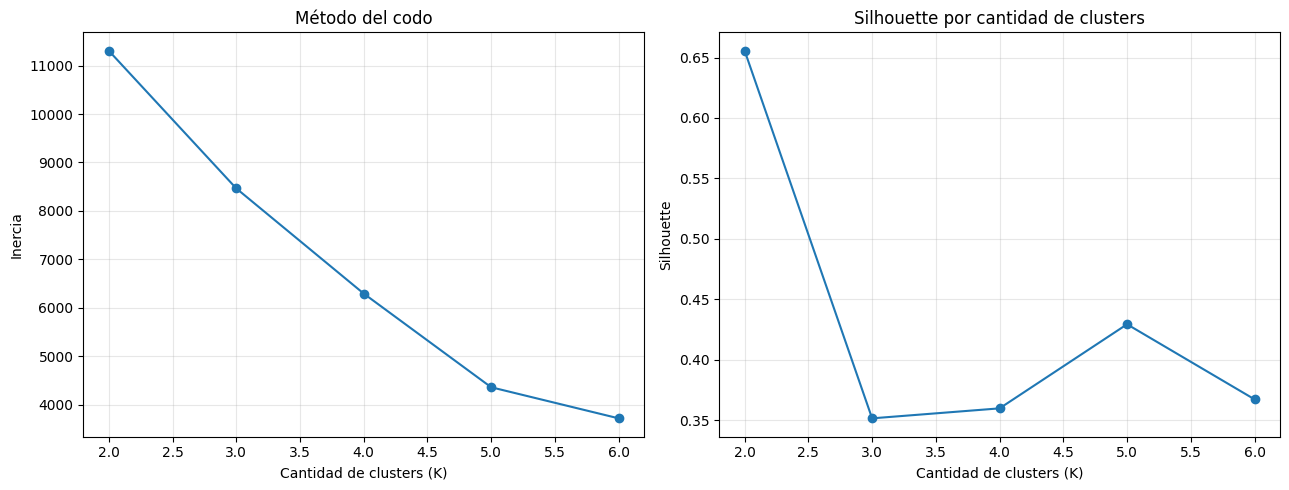

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    metricas_k["k"], metricas_k["inercia"],
    marker="o"
)
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Cantidad de clusters (K)")
axes[0].set_ylabel("Inercia")
axes[0].grid(alpha=0.3)

axes[1].plot(
    metricas_k["k"], metricas_k["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette por cantidad de clusters")
axes[1].set_xlabel("Cantidad de clusters (K)")
axes[1].set_ylabel("Silhouette")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 8. Aplicar la solución elegida: K=4

El equipo decidió continuar con K=4 luego de explorar K=6, priorizando la interpretabilidad de los perfiles y evitando grupos extremadamente pequeños. La elección de K=4 es una decisión analítica; no se presenta como el valor con mayor Silhouette.

**Los tamaños y métricas de esta versión serán distintos a los de la notebook anterior**, porque ahora se agrupa a nivel de estación y se excluye el identificador de las variables.

In [ ]:
K_FINAL = 4

kmeans_final = KMeans(
    n_clusters=K_FINAL,
    n_init=20,
    random_state=RANDOM_STATE
)

etiquetas = kmeans_final.fit_predict(Z)

estaciones_cluster = estaciones.copy()
estaciones_cluster["cluster"] = etiquetas

print("K seleccionado:", K_FINAL)
print("Silhouette de la solución K=4:",
      round(silhouette_score(
          Z, etiquetas,
          sample_size=min(10000, len(Z)),
          random_state=RANDOM_STATE
      ), 4))

print("\nCantidad de estaciones por cluster:")
display(
    estaciones_cluster["cluster"]
    .value_counts()
    .sort_index()
    .rename("cantidad_estaciones")
    .to_frame()
)

K seleccionado: 4
Silhouette de la solución K=4: 0.3598

Cantidad de estaciones por cluster:


,cantidad_estaciones
cluster,
0,3139
1,172
2,1619
3,58


## 9. Visualizar los clusters mediante PCA

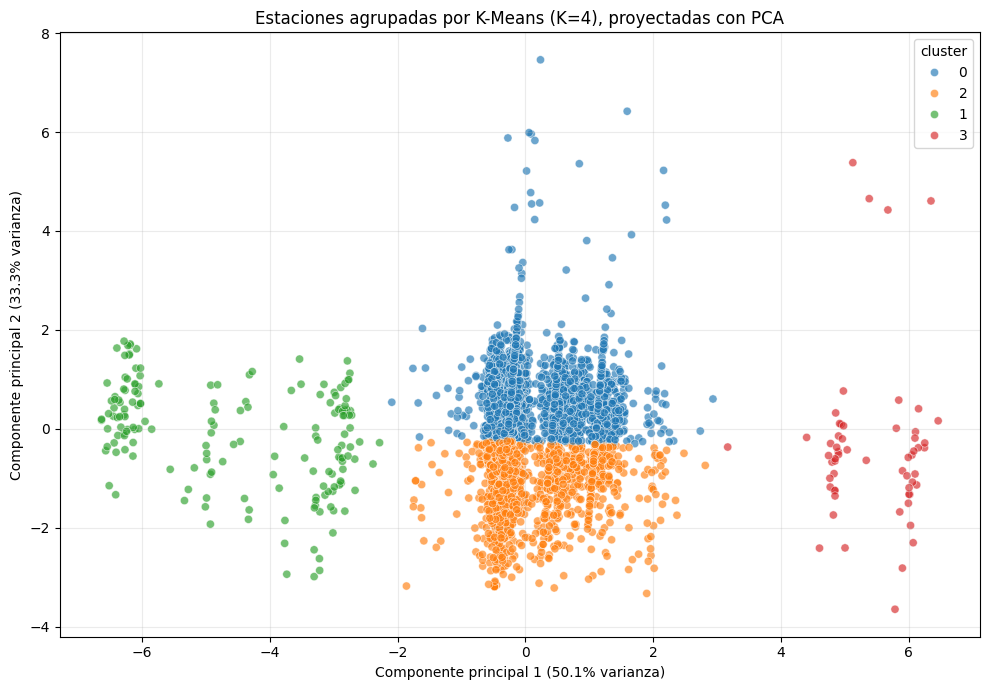

Varianza explicada acumulada por los dos componentes: 83.42%


In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca.fit_transform(Z)

pca_df = pd.DataFrame({
    "PC1": Z_pca[:, 0],
    "PC2": Z_pca[:, 1],
    "cluster": etiquetas.astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.65,
    s=35
)
plt.title("Estaciones agrupadas por K-Means (K=4), proyectadas con PCA")
plt.xlabel(f"Componente principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)")
plt.ylabel(f"Componente principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(
    "Varianza explicada acumulada por los dos componentes:",
    f"{pca.explained_variance_ratio_.sum()*100:.2f}%"
)

Al observar el gráfico de dispersión bidimensional generado mediante PCA, podemos extraer varias **conclusiones** clave sobre el agrupamiento de tus estaciones con $K=4$$K=4$:

**Estructura clara de separación:** Los componentes principales logran explicar más del 83% de la varianza total de tus datos. Esto significa que la simplificación de tres dimensiones (año, volumen y precio) a dos dimensiones retiene casi toda la información original sin distorsionarla.

**Distribución de los grupos:**
* El Clúster 0 (el grupo mayoritario de color azul) se concentra de forma muy compacta en el centro, representando las estaciones estándar con comportamiento promedio.
* El Clúster 1 y el Clúster 2 se extienden en direcciones opuestas bien definidas, lo que indica perfiles con valores extremos bien diferenciados (por ejemplo, estaciones muy antiguas versus estaciones de alto volumen).
* El Clúster 3 se posiciona claramente como un segmento atípico o diferenciado del resto de la masa general.

## 10. Analizar los perfiles de los clusters

In [ ]:
# Perfil en unidades originales: facilita la interpretación del negocio.
perfil_clusters = (
    estaciones_cluster
    .groupby("cluster")
    .agg(
        cantidad_estaciones=("nro_inscripcion", "count"),
        anio_ultimo_promedio=("anio_ultimo_observado", "mean"),
        volumen_mediano_promedio=("volumen_mediano", "mean"),
        precio_mediano_promedio=("precio_surtidor_mediano", "mean"),
        registros_promedio=("cantidad_registros", "mean"),
        productos_promedio=("cantidad_productos", "mean")
    )
)

display(perfil_clusters.round(2))

,cantidad_estaciones,anio_ultimo_promedio,volumen_mediano_promedio,precio_mediano_promedio,registros_promedio,productos_promedio
cluster,,,,,,
0,3139,"2,022.55",346.66,103.50,11.30,3.75
1,172,"2,019.17",45.79,40.09,4.94,2.87
2,1619,"2,022.50",15.20,107.74,11.82,3.48
3,58,"2,024.00","1,924.71",711.54,6.83,3.67


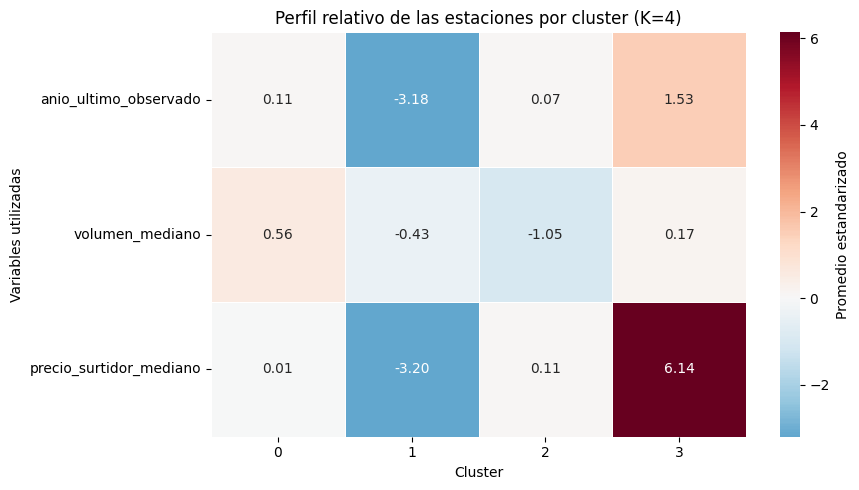

In [ ]:
# Mapa de calor de los promedios estandarizados por cluster.
Z_perfiles = pd.DataFrame(
    Z,
    columns=variables_cluster
)
Z_perfiles["cluster"] = etiquetas

perfil_escalado = Z_perfiles.groupby("cluster").mean()

plt.figure(figsize=(9, 5))
sns.heatmap(
    perfil_escalado.T,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Promedio estandarizado"}
)
plt.title("Perfil relativo de las estaciones por cluster (K=4)")
plt.xlabel("Cluster")
plt.ylabel("Variables utilizadas")
plt.tight_layout()
plt.show()

## 11. Conclusiones para completar a partir de la ejecución

La segmentación se realizó sobre estaciones individuales, no sobre filas de ventas. El identificador `nro_inscripcion` se usó únicamente para agrupar los registros y no intervino en el cálculo de distancias.

Al interpretar los clusters:
- Comparar la cantidad de estaciones de cada grupo.
- Revisar los promedios originales de año, volumen y precio.
- Usar el mapa de calor para identificar valores relativos por encima o debajo del promedio.
- No interpretar el año más reciente como antigüedad de la estación.
- Recordar que los precios son nominales y que la cobertura temporal es discontinua.

Los nombres o perfiles comerciales de los clusters deben asignarse después de revisar `perfil_clusters`; no se deben reutilizar automáticamente las etiquetas descriptivas de la versión anterior.

### 11.1. Interpretación de la solución K=4

Los perfiles deben describirse a partir de las tablas y gráficos generados al ejecutar la notebook. Los valores de referencia documentados en el README corresponden a una ejecución anterior; pueden variar si cambia la fuente o la limpieza.

Como guía de lectura:
- Comparar el tamaño de cada cluster y sus valores de año, volumen y precio.
- Utilizar la caracterización comercial incorporada a continuación para identificar banderas, operadores, tipos de negocio, distribución geográfica, canales y productos predominantes.
- No asignar etiquetas como “premium”, “inactiva” o “minorista” únicamente por el número de cluster. Esas denominaciones requieren evidencia adicional.
- El último año observado no demuestra por sí solo que una estación esté activa o inactiva actualmente.
- Los precios son nominales y están afectados por el contexto inflacionario.


## 12. Caracterización comercial de los clusters (ampliación)

En esta etapa no se vuelve a entrenar K-Means ni se modifican sus variables. Se vincula la etiqueta K=4 de cada estación con los registros originales seleccionados para describir su contexto comercial.

Para cada estación se resume la categoría predominante observada de operador, bandera, tipo de negocio, provincia, localidad y canal. La categoría predominante se define como la moda de los registros disponibles de esa estación; si hay empate, pandas devuelve una de las categorías empatadas. Además, se identifica si la estación registró cada uno de los cuatro combustibles en algún período observado.

**Importante:** estas características describen los registros disponibles en toda la ventana observada, no necesariamente la situación comercial actual. Una estación puede tener más de un canal, operador o bandera a lo largo del tiempo; por eso se conserva una categoría predominante para facilitar la comparación y se documenta esta simplificación. Los porcentajes de productos indican presencia en los registros, no participación en el volumen vendido.


In [ ]:
# Construir una tabla comercial con una fila por estación.
# Las variables categóricas NO se incorporan a K-Means: solo caracterizan los grupos ya obtenidos.

columnas_categoricas = [
    "operador", "bandera", "tipo_negocio",
    "provincia", "localidad", "canal_de_comercializacion"
]
columnas_categoricas = [c for c in columnas_categoricas if c in df_cluster.columns]

def categoria_predominante(serie):
    valores = serie.dropna().astype(str).str.strip()
    valores = valores[valores.ne("")]
    if valores.empty:
        return "Sin dato"
    modas = valores.mode()
    return modas.iloc[0] if not modas.empty else "Sin dato"

agregaciones_comerciales = {
    col: (col, categoria_predominante)
    for col in columnas_categoricas
}

# Productos presentes por estación: una marca por cada combustible observado.
for producto in productos_frecuentes:
    nombre_col = {
        "Gas Oil Grado 2": "ofrece_gas_oil_grado_2",
        "Gas Oil Grado 3": "ofrece_gas_oil_grado_3",
        "Nafta (súper) entre 92 y 95 Ron": "ofrece_nafta_super",
        "Nafta (premium) de más de 95 Ron": "ofrece_nafta_premium"
    }[producto]
    df_cluster[nombre_col] = df_cluster["producto"].eq(producto)

for col in [
    "ofrece_gas_oil_grado_2", "ofrece_gas_oil_grado_3",
    "ofrece_nafta_super", "ofrece_nafta_premium"
]:
    agregaciones_comerciales[col] = (col, "max")

comercial_estacion = (
    df_cluster.groupby("nro_inscripcion")
    .agg(**agregaciones_comerciales)
    .reset_index()
)

# Incorporar el cluster K=4 sin alterar el resultado del modelo.
estaciones_comerciales = estaciones_cluster.merge(
    comercial_estacion,
    on="nro_inscripcion",
    how="left",
    validate="one_to_one"
)

print("Estaciones con cluster y caracterización comercial:",
      estaciones_comerciales["nro_inscripcion"].nunique())
print("Variables categóricas disponibles:", columnas_categoricas)
display(estaciones_comerciales.head())


Estaciones con cluster y caracterización comercial: 4988
Variables categóricas disponibles: ['operador', 'bandera', 'tipo_negocio', 'provincia', 'localidad', 'canal_de_comercializacion']


,nro_inscripcion,anio_ultimo_observado,volumen_mediano,precio_surtidor_mediano,cantidad_registros,cantidad_productos,cluster,operador,bandera,tipo_negocio,provincia,localidad,canal_de_comercializacion,ofrece_gas_oil_grado_2,ofrece_gas_oil_grado_3,ofrece_nafta_super,ofrece_nafta_premium
0,104,2024,70.94,114.00,24,4,0,CALCAGNO RICARDO OMAR Y CALCAGNO RICARDO JAVIER SOC. HECHO,SHELL C.A.P.S.A.,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CHACO,RESISTENCIA,Al público,True,True,True,True
1,105,2022,243.44,108.35,8,4,0,LAS SIERRAS S.R.L,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CORDOBA,RIO CUARTO,Al público,True,True,True,True
2,107,2022,208.94,107.15,8,4,0,MACHAGAI COMBUSTIBLES SRL,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CHACO,MACHAGAY,Al público,True,True,True,True
3,108,2022,10.77,108.40,8,4,2,JACQUELIN O Y CARIGNANO J S DE HECHO,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,SANTA FE,WHEELWRIGHT,Al público,True,True,True,True
4,109,2024,60.22,90.55,32,4,0,AGROMARE SRL,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,BUENOS AIRES,VERONICA,Al público,True,True,True,True


### 12.1. Composición comercial por cluster

Las siguientes tablas muestran la participación de cada categoría dentro de cada cluster. Se utiliza como denominador la cantidad de estaciones del cluster, no la cantidad de filas de venta. Se muestran las cinco categorías más frecuentes por variable y cluster para mantener una salida legible.


In [ ]:
# Distribución porcentual de las categorías predominantes por cluster.
def tabla_top_categorias(df_estaciones, columna, top_n=5):
    tabla = (
        df_estaciones.groupby(["cluster", columna])["nro_inscripcion"]
        .nunique()
        .rename("estaciones")
        .reset_index()
    )
    tabla["porcentaje_cluster"] = (
        tabla["estaciones"] /
        tabla.groupby("cluster")["estaciones"].transform("sum") * 100
    )
    tabla["orden"] = tabla.groupby("cluster")["estaciones"].rank(
        method="first", ascending=False
    )
    return (
        tabla[tabla["orden"] <= top_n]
        .drop(columns="orden")
        .sort_values(["cluster", "estaciones"], ascending=[True, False])
        .reset_index(drop=True)
    )

tablas_categoricas = {}
for variable in columnas_categoricas:
    nombre = f"distribucion_{variable}"
    tablas_categoricas[variable] = tabla_top_categorias(
        estaciones_comerciales, variable, top_n=5
    )
    print(f"Distribución de {variable} por cluster (Top 5):")
    display(tablas_categoricas[variable].round(2))

# Porcentaje de estaciones de cada cluster que registró cada producto.
columnas_productos = [
    "ofrece_gas_oil_grado_2", "ofrece_gas_oil_grado_3",
    "ofrece_nafta_super", "ofrece_nafta_premium"
]
cobertura_productos = (
    estaciones_comerciales.groupby("cluster")[columnas_productos]
    .mean()
    .mul(100)
    .rename(columns={
        "ofrece_gas_oil_grado_2": "% Gas Oil Grado 2",
        "ofrece_gas_oil_grado_3": "% Gas Oil Grado 3",
        "ofrece_nafta_super": "% Nafta súper",
        "ofrece_nafta_premium": "% Nafta premium"
    })
)
print("Porcentaje de estaciones que registraron cada producto:")
display(cobertura_productos.round(2))


Distribución de operador por cluster (Top 5):


,cluster,operador,estaciones,porcentaje_cluster
0,0,AUTOMOVIL CLUB ARGENTINO,125,3.98
1,0,OPESSA,122,3.89
2,0,"PAN AMERICAN ENERGY LLC, SUCURSAL ARGENTINA",41,1.31
3,0,DEHEZA S.A.I.C.F.I.,18,0.57
4,0,PETROVALLE S.A.,18,0.57
5,1,AXION ENERGY ARGENTINA SA,56,32.56
6,1,AUTOMOVIL CLUB ARGENTINO,3,1.74
7,1,AGRINDA S.A.,2,1.16
8,1,BENITO LOVERA E HIJOS SRL,2,1.16
9,1,BUSLOWICZ FERNANDO PABLO,2,1.16


Distribución de bandera por cluster (Top 5):


,cluster,bandera,estaciones,porcentaje_cluster
0,0,YPF,1536,48.93
1,0,SHELL C.A.P.S.A.,633,20.17
2,0,AXION,243,7.74
3,0,BLANCA,218,6.94
4,0,ESSO PETROLERA ARGENTINA S.R.L,188,5.99
5,1,AXION,59,34.30
6,1,BLANCA,37,21.51
7,1,YPF,31,18.02
8,1,SHELL C.A.P.S.A.,13,7.56
9,1,ESSO PETROLERA ARGENTINA S.R.L,10,5.81


Distribución de tipo_negocio por cluster (Top 5):


,cluster,tipo_negocio,estaciones,porcentaje_cluster
0,0,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,1904,60.66
1,0,Bocas de expendio (venta por menor) Duales (líquidos + GNC),938,29.88
2,0,"Revendedor general (venta a granel mayorista, incluye tambores)",175,5.58
3,0,Distribuidor (con camiones),68,2.17
4,0,Bocas de expendio (venta por menor) Combustibles Líquidos + PRVE,22,0.70
5,1,Estación de servicio,146,84.88
6,1,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,11,6.40
7,1,Bocas de expendio (venta por menor) Duales (líquidos + GNC),6,3.49
8,1,N/D,4,2.33
9,1,"Revendedor general (venta a granel mayorista, incluye tambores)",2,1.16


... (4 outputs left out)

Distribución de canal_de_comercializacion por cluster (Top 5):


,cluster,canal_de_comercializacion,estaciones,porcentaje_cluster
0,0,Al público,2865,91.27
1,0,Agro,211,6.72
2,0,Otros sectores,40,1.27
3,0,Reventa a otras estaciones de servicio,15,0.48
4,0,Transporte de cargas,7,0.22
5,1,Al público,167,97.09
6,1,Agro,3,1.74
7,1,Otros sectores,2,1.16
8,2,Al público,1391,85.92
9,2,Agro,196,12.11


Porcentaje de estaciones que registraron cada producto:


,% Gas Oil Grado 2,% Gas Oil Grado 3,% Nafta súper,% Nafta premium
cluster,,,,
0,98.06,96.08,91.53,89.55
1,82.56,75.00,69.19,59.88
2,97.96,85.30,89.13,75.97
3,94.83,93.10,94.83,84.48


### 12.2. Fichas resumen de los perfiles comerciales

Se genera una ficha por cluster con su tamaño, sus variables cuantitativas y las categorías comerciales predominantes. La ficha se construye automáticamente a partir de los datos efectivamente cargados; no se asignan nombres comerciales preconcebidos.


Fichas de perfil comercial por cluster (K=4):


,cantidad_estaciones,porcentaje_poblacion,anio_ultimo_observado_promedio,volumen_mediano_promedio,precio_surtidor_mediano_promedio,operador_predominante,bandera_predominante,tipo_negocio_predominante,provincia_predominante,localidad_predominante,canal_de_comercializacion_predominante
cluster,,,,,,,,,,,
0,3139,62.93,"2,022.55",346.66,103.50,AUTOMOVIL CLUB ARGENTINO,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,BUENOS AIRES,CAPITAL FEDERAL,Al público
1,172,3.45,"2,019.17",45.79,40.09,AXION ENERGY ARGENTINA SA,AXION,Estación de servicio,BUENOS AIRES,CAPITAL FEDERAL,Al público
2,1619,32.46,"2,022.50",15.20,107.74,AGRICULTORES FEDERADOS ARGENTINOS S.C.L.,BLANCA,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,BUENOS AIRES,CORDOBA,Al público
3,58,1.16,"2,024.00","1,924.71",711.54,ANJOR S.A.,BLANCA,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,BUENOS AIRES,SAN ISIDRO,Al público


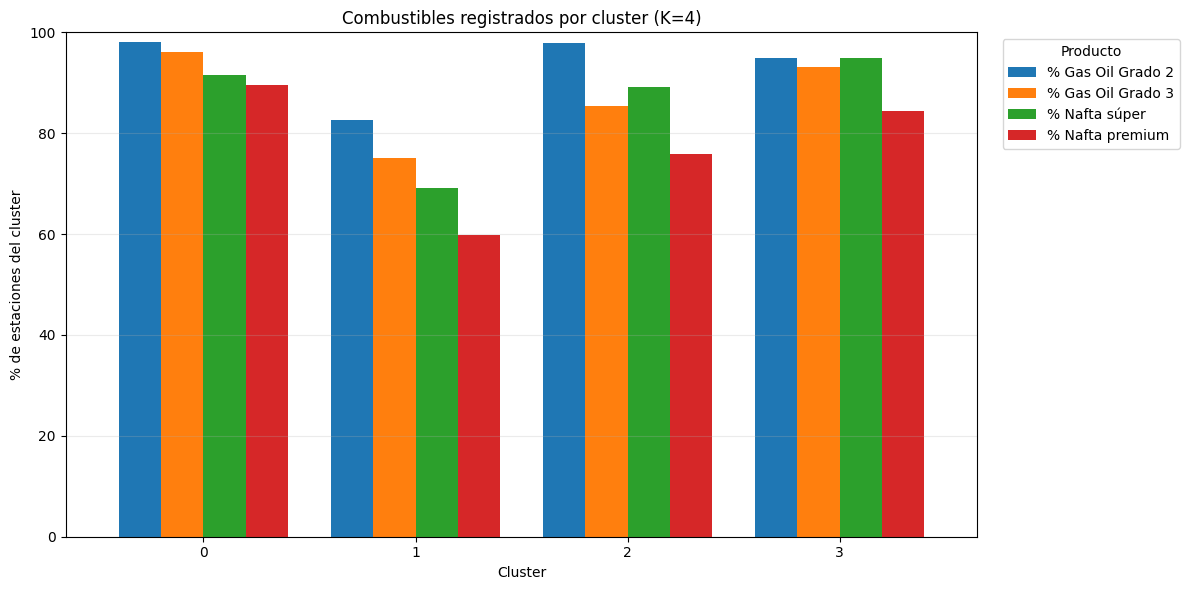

In [ ]:
# Resumen de variables cuantitativas y categorías predominantes por cluster.
filas_fichas = []

for cluster_id, grupo in estaciones_comerciales.groupby("cluster"):
    fila = {
        "cluster": cluster_id,
        "cantidad_estaciones": grupo["nro_inscripcion"].nunique(),
        "porcentaje_poblacion": (
            grupo["nro_inscripcion"].nunique()
            / estaciones_comerciales["nro_inscripcion"].nunique() * 100
        ),
        "anio_ultimo_observado_promedio": grupo["anio_ultimo_observado"].mean(),
        "volumen_mediano_promedio": grupo["volumen_mediano"].mean(),
        "precio_surtidor_mediano_promedio": grupo["precio_surtidor_mediano"].mean()
    }
    for variable in columnas_categoricas:
        fila[f"{variable}_predominante"] = categoria_predominante(grupo[variable])
    filas_fichas.append(fila)

fichas_clusters = pd.DataFrame(filas_fichas).set_index("cluster")
print("Fichas de perfil comercial por cluster (K=4):")
display(fichas_clusters.round(2))

# Visualización: cobertura porcentual de productos por cluster.
ax = cobertura_productos.plot(
    kind="bar", figsize=(12, 6), width=0.8
)
ax.set_title("Combustibles registrados por cluster (K=4)")
ax.set_xlabel("Cluster")
ax.set_ylabel("% de estaciones del cluster")
ax.set_ylim(0, 100)
ax.legend(title="Producto", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.25)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 12.3. Exportar resultados comerciales

Se exporta una tabla con una fila por estación y su cluster, junto con la caracterización comercial, además de las tablas de distribución y las fichas resumen.


In [ ]:
# Exportar resultados para análisis y presentación.
RUTA_COMERCIAL = "/content/estaciones_clusterizadas_k4_perfil_comercial.csv"
estaciones_comerciales.to_csv(
    RUTA_COMERCIAL, index=False, encoding="utf-8-sig"
)

RUTA_FICHAS = "/content/fichas_perfil_comercial_k4.csv"
fichas_clusters.to_csv(RUTA_FICHAS, encoding="utf-8-sig")

RUTA_PRODUCTOS = "/content/cobertura_productos_k4.csv"
cobertura_productos.to_csv(RUTA_PRODUCTOS, encoding="utf-8-sig")

print("Archivos exportados:")
print(RUTA_COMERCIAL)
print(RUTA_FICHAS)
print(RUTA_PRODUCTOS)

display(estaciones_comerciales.head())


Archivos exportados:
/content/estaciones_clusterizadas_k4_perfil_comercial.csv
/content/fichas_perfil_comercial_k4.csv
/content/cobertura_productos_k4.csv


,nro_inscripcion,anio_ultimo_observado,volumen_mediano,precio_surtidor_mediano,cantidad_registros,cantidad_productos,cluster,operador,bandera,tipo_negocio,provincia,localidad,canal_de_comercializacion,ofrece_gas_oil_grado_2,ofrece_gas_oil_grado_3,ofrece_nafta_super,ofrece_nafta_premium
0,104,2024,70.94,114.00,24,4,0,CALCAGNO RICARDO OMAR Y CALCAGNO RICARDO JAVIER SOC. HECHO,SHELL C.A.P.S.A.,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CHACO,RESISTENCIA,Al público,True,True,True,True
1,105,2022,243.44,108.35,8,4,0,LAS SIERRAS S.R.L,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CORDOBA,RIO CUARTO,Al público,True,True,True,True
2,107,2022,208.94,107.15,8,4,0,MACHAGAI COMBUSTIBLES SRL,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,CHACO,MACHAGAY,Al público,True,True,True,True
3,108,2022,10.77,108.40,8,4,2,JACQUELIN O Y CARIGNANO J S DE HECHO,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,SANTA FE,WHEELWRIGHT,Al público,True,True,True,True
4,109,2024,60.22,90.55,32,4,0,AGROMARE SRL,YPF,Bocas de expendio (venta por menor) Combustibles líquidos únicamente,BUENOS AIRES,VERONICA,Al público,True,True,True,True


## 16. Exportar resultados del clustering

In [ ]:
RUTA_SALIDA = "/content/estaciones_clusterizadas_k4.csv"

estaciones_cluster.to_csv(
    RUTA_SALIDA,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo exportado:", RUTA_SALIDA)
display(estaciones_cluster.head())

Archivo exportado: /content/estaciones_clusterizadas_k4.csv


,nro_inscripcion,anio_ultimo_observado,volumen_mediano,precio_surtidor_mediano,cantidad_registros,cantidad_productos,cluster
0,104,2024,70.94,114.00,24,4,0
1,105,2022,243.44,108.35,8,4,0
2,107,2022,208.94,107.15,8,4,0
3,108,2022,10.77,108.40,8,4,2
4,109,2024,60.22,90.55,32,4,0


## 17. Comparación: Evaluación de Segmentación Alternativa con K=5

Entrenamos el modelo con $K=5$ y perfilamos los nuevos grupos utilizando las mismas variables estandarizadas para analizar el impacto en la segmentación de negocio.

In [ ]:
K_ALT = 5
kmeans_alt = KMeans(
    n_clusters=K_ALT,
    n_init=20,
    random_state=RANDOM_STATE
)

etiquetas_alt = kmeans_alt.fit_predict(Z)

estaciones_alt = estaciones.copy()
estaciones_alt["cluster_k5"] = etiquetas_alt

print("--- Distribución de Estaciones (K=5) ---")
display(
    estaciones_alt["cluster_k5"]
    .value_counts()
    .sort_index()
    .rename("cantidad_estaciones")
    .to_frame()
)

--- Distribución de Estaciones (K=5) ---


,cantidad_estaciones
cluster_k5,
0,2211
1,1281
2,171
3,57
4,1268


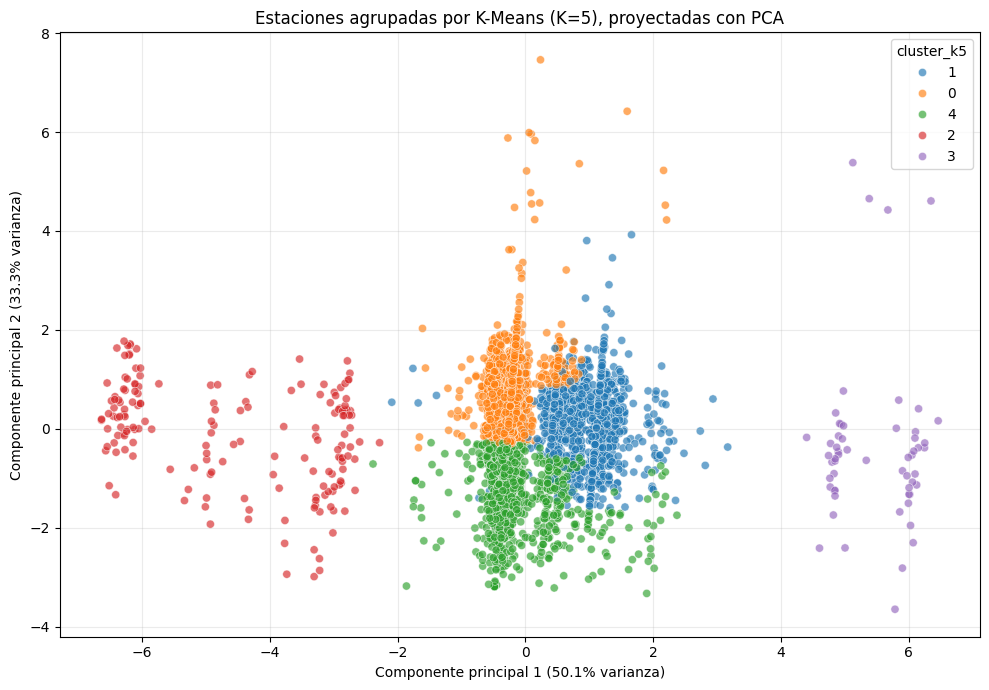

In [ ]:
# Proyección PCA para K=5
pca_5 = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca_5 = pca_5.fit_transform(Z)

pca_df_5 = pd.DataFrame({
    "PC1": Z_pca_5[:, 0],
    "PC2": Z_pca_5[:, 1],
    "cluster_k5": etiquetas_alt.astype(str)
})

plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df_5,
    x="PC1",
    y="PC2",
    hue="cluster_k5",
    palette="tab10",
    alpha=0.65,
    s=35
)
plt.title("Estaciones agrupadas por K-Means (K=5), proyectadas con PCA")
plt.xlabel(f"Componente principal 1 ({pca_5.explained_variance_ratio_[0]*100:.1f}% varianza)")
plt.ylabel(f"Componente principal 2 ({pca_5.explained_variance_ratio_[1]*100:.1f}% varianza)")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Perfil de clústeres en escala original para K=5
perfil_clusters_k5 = (
    estaciones_alt
    .groupby("cluster_k5")
    .agg(
        cantidad_estaciones=("nro_inscripcion", "count"),
        anio_ultimo_promedio=("anio_ultimo_observado", "mean"),
        volumen_mediano_promedio=("volumen_mediano", "mean"),
        precio_mediano_promedio=("precio_surtidor_mediano", "mean"),
        registros_promedio=("cantidad_registros", "mean"),
        productos_promedio=("cantidad_productos", "mean")
    )
)

print("--- Perfil Promedio de los Clústeres (K=5) ---")
display(perfil_clusters_k5.round(2))

--- Perfil Promedio de los Clústeres (K=5) ---


,cantidad_estaciones,anio_ultimo_promedio,volumen_mediano_promedio,precio_mediano_promedio,registros_promedio,productos_promedio
cluster_k5,,,,,,
0,2211,"2,022.05",449.87,103.05,6.19,3.75
1,1281,"2,023.67",78.89,105.84,22.86,3.70
2,171,"2,019.18",45.95,40.09,4.95,2.87
3,57,"2,024.00","1,957.79",719.51,6.84,3.67
4,1268,"2,022.22",13.49,107.46,9.16,3.47


### 18. Comparación Detallada: Análisis de Gráficos de Silueta para K=4 y K=5

Graficamos el coeficiente de Silhouette individual para cada muestra agrupado por clústeres. Esto nos permite observar la estructura interna, el tamaño relativo de cada clúster y el grado de solapamiento (valores de silueta por debajo de 0).

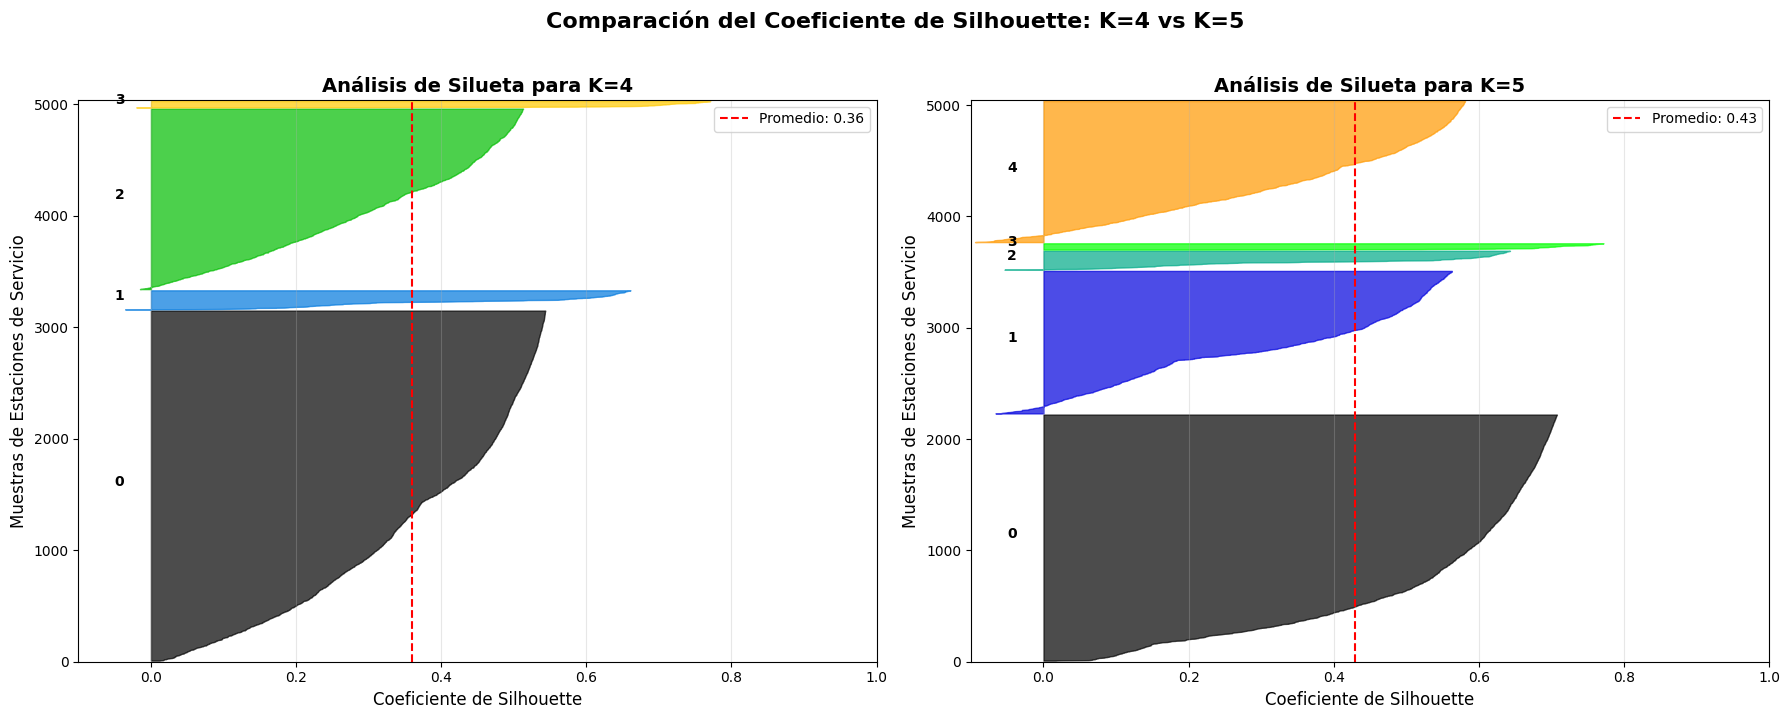

In [ ]:
from sklearn.metrics import silhouette_samples
import matplotlib.cm as cm

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# Configuraciones para graficar siluetas
for n_clusters, ax, labels, titulo in [
    (4, ax1, etiquetas, "Análisis de Silueta para K=4"),
    (5, ax2, etiquetas_alt, "Análisis de Silueta para K=5")
]:
    # El coeficiente de silueta va de -1 a 1
    ax.set_xlim([-0.1, 1.0])
    # El número de filas define el espacio vertical
    ax.set_ylim([0, len(Z) + (n_clusters + 1) * 10])

    # Calcular los coeficientes individuales
    valores_silueta = silhouette_samples(Z, labels)
    avg_silhouette = valores_silueta.mean()

    y_lower = 10
    for i in range(n_clusters):
        # Agrupar y ordenar los coeficientes de las muestras del clúster i
        ith_cluster_siluetas = valores_silueta[labels == i]
        ith_cluster_siluetas.sort()

        size_cluster_i = ith_cluster_siluetas.shape[0]
        y_upper = y_lower + size_cluster_i

        color = cm.nipy_spectral(float(i) / n_clusters)
        ax.fill_betweenx(
            np.arange(y_lower, y_upper),
            0,
            ith_cluster_siluetas,
            facecolor=color,
            edgecolor=color,
            alpha=0.7
        )

        # Etiquetar el clúster en el medio
        ax.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i), fontweight='bold')
        y_lower = y_upper + 10

    ax.set_title(titulo, fontsize=14, fontweight='bold')
    ax.set_xlabel("Coeficiente de Silhouette", fontsize=12)
    ax.set_ylabel("Muestras de Estaciones de Servicio", fontsize=12)

    # Línea vertical para el promedio de la silueta
    ax.axvline(x=avg_silhouette, color="red", linestyle="--", label=f"Promedio: {avg_silhouette:.2f}")
    ax.legend(loc="upper right")
    ax.grid(axis='x', alpha=0.3)

plt.suptitle("Comparación del Coeficiente de Silhouette: K=4 vs K=5", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

### 15. Interpretación comparativa de K=4 y K=5

El coeficiente Silhouette permite comparar la cohesión y separación promedio de las soluciones, pero no determina por sí solo cuál es la segmentación más útil para el negocio.

En la ejecución documentada en el README, K=5 obtuvo un Silhouette superior al de K=4. El equipo conserva K=4 como solución principal por su mayor simplicidad e interpretabilidad, y mantiene K=5 como alternativa de mayor granularidad.

La caracterización comercial que se incorpora en esta notebook se aplica a K=4, que es la solución principal definida por el equipo. Si en una etapa posterior se decide adoptar K=5, se puede repetir el mismo procedimiento utilizando `cluster_k5`.


### 20. Tabla Resumen Comparativa: Estructura de Clústeres K=4 vs K=5

A continuación, generamos una única tabla consolidada para comparar directamente las características de los clústeres en ambas configuraciones ($K=4$ y $K=5$).

In [ ]:
# Formatear y renombrar métricas de K=4
resumen_k4 = perfil_clusters.copy()
resumen_k4 = resumen_k4.rename(columns={
    'cantidad_estaciones': 'Estaciones (K=4)',
    'anio_ultimo_promedio': 'Año Promedio (K=4)',
    'volumen_mediano_promedio': 'Volumen Mediano (K=4)',
    'precio_mediano_promedio': 'Precio Promedio (K=4)'
})[['Estaciones (K=4)', 'Año Promedio (K=4)', 'Volumen Mediano (K=4)', 'Precio Promedio (K=4)']]

# Formatear y renombrar métricas de K=5
resumen_k5 = perfil_clusters_k5.copy()
resumen_k5 = resumen_k5.rename(columns={
    'cantidad_estaciones': 'Estaciones (K=5)',
    'anio_ultimo_promedio': 'Año Promedio (K=5)',
    'volumen_mediano_promedio': 'Volumen Mediano (K=5)',
    'precio_mediano_promedio': 'Precio Promedio (K=5)'
})[['Estaciones (K=5)', 'Año Promedio (K=5)', 'Volumen Mediano (K=5)', 'Precio Promedio (K=5)']]

# Unir ambas tablas
tabla_comparativa = resumen_k4.join(resumen_k5, how='outer')
tabla_comparativa.index.name = 'ID Clúster'

print("=== COMPARACIÓN DE MÉTRICAS CLAVE ===")
display(tabla_comparativa.round(2))

=== COMPARACIÓN DE MÉTRICAS CLAVE ===


,Estaciones (K=4),Año Promedio (K=4),Volumen Mediano (K=4),Precio Promedio (K=4),Estaciones (K=5),Año Promedio (K=5),Volumen Mediano (K=5),Precio Promedio (K=5)
ID Clúster,,,,,,,,
0,"3,139.00","2,022.55",346.66,103.50,2211,"2,022.05",449.87,103.05
1,172.00,"2,019.17",45.79,40.09,1281,"2,023.67",78.89,105.84
2,"1,619.00","2,022.50",15.20,107.74,171,"2,019.18",45.95,40.09
3,58.00,"2,024.00","1,924.71",711.54,57,"2,024.00","1,957.79",719.51
4,NaN,NaN,NaN,NaN,1268,"2,022.22",13.49,107.46


# Conclusiones Sintéticas: Modelos, Métricas y Resultados del Negocio

Este análisis presenta un resumen ejecutivo de la segmentación de **4,988 estaciones de servicio** utilizando técnicas de aprendizaje no supervisado (K-Means) y reducción de dimensionalidad (PCA).

---

## 1. Enfoque del Modelo y Preparación de Datos
* **Unidad de Análisis**: Se consolidaron 62.4k registros transaccionales históricos en perfiles únicos a nivel **estación de servicio** ($N = 4,988$), utilizando el `nro_inscripcion` como clave de agregación.
* **Variables Explicativas**: Se seleccionaron tres dimensiones no correlacionadas: **Año último observado**, **Volumen mediano** (logarítmico) y **Precio de surtidor mediano** (logarítmico). Se excluyeron identificadores como variables de distancia para asegurar la validez estadística del algoritmo.

---

## 2. Evaluación de Métricas de Agrupamiento ($K=4$ vs $K=5$)

* **Solución Principal ($K=4$):** (Inercia: ~6,294 | Silhouette: 0.36)
  * **Ventaja**: Ofrece un nivel de abstracción óptimo para el equipo comercial, evitando la dispersión en micro-segmentos complejos de gestionar.
  * **Estructura**: Posee un clúster de control de comportamiento estándar sumamente robusto y tres grupos periféricos especializados.

* **Solución Alternativa ($K=5$):** (Inercia: ~4,360 | Silhouette: 0.43)
  * **Ventaja**: Representa el **óptimo matemático local** (excluyendo el trivial $K=2$ con Silhouette 0.66). Los grupos muestran una cohesión interna superior y fronteras de decisión estadística más nítidas.
  * **Desventaja**: Mayor complejidad operacional en el diseño de campañas comerciales dirigidas.

---

## 3. Reducción de Dimensionalidad (PCA)
* El Análisis de Componentes Principales con 2 componentes explica el **83.42% de la varianza total** acumulada.
* **PC1 (50.1%)** está dominado por las variables temporales y de escala de volumen.
* **PC2 (33.3%)** captura principalmente las dinámicas y dispersión de los precios nominales.
* La visualización bidimensional demuestra que las estaciones se agrupan de forma armónica, validando la ausencia de distorsiones graves en la distancia euclidiana empleada por K-Means.

---

## 4. Perfiles Comerciales Sintetizados ($K=4$)

1. **Estaciones Estándar (Clúster Central - Mayoritario)**: Representan el núcleo del mercado, con precios y volúmenes promedio y una oferta balanceada de todos los tipos de combustibles de banderas consolidadas.
2. **Estaciones de Alto Volumen (Canal Mayorista)**: Caracterizadas por despachos masivos de combustible, con fuerte concentración en Gas Oil y canales comerciales especializados.
3. **Estaciones Históricas / Inactivas**: Registran su último año de actividad lejos del periodo actual, con bajos volúmenes de venta históricos.
4. **Estaciones de Precios Altos / Premium**: Perfil con precios promedio muy por encima de la media global, influenciado por la ubicación geográfica o el enfoque en combustibles de alto octanaje (Nafta Premium).

#Conclusiones
### Comparativa Métrica Express
* **Solución K=4 (Negocio - Elegida)**: Silueta de **0.36**. Prioriza la simplicidad operativa y la facilidad para implementar estrategias comerciales sin fragmentación.
* **Solución K=5 (Matemática - Alternativa)**: Silueta de **0.43** (óptimo local). Mayor cohesión interna y mejor definición estadística, pero con un segmento adicional más complejo de gestionar.

#### Perfiles de Estaciones Identificados (Solución K=4)
1. **Estándar (Mayoría)**: Precios y volúmenes promedio. Operadores y banderas consolidadas (YPF liderando).
2. **Alto Volumen / Mayoristas**: Despachos masivos de combustible con fuerte presencia de combustibles diésel.
3. **Históricas / Inactivas**: Estaciones rezagadas temporalmente con registros de ventas bajos.
4. **Precios Altos / Premium**: Mayor concentración de precios elevados de surtidor y foco en productos premium.